In [1]:
%pip install pandas numpy seaborn scikit-learn nltk lime shap
%pip install torch "transformers>=4.40"
%pip install tf-keras

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import re
import random
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from lime.lime_text import LimeTextExplainer

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

c:\Users\LUIRYS SILVA\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cpu


In [16]:
df = pd.read_csv('../spam.csv')

In [17]:
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [18]:
df.shape

(5572, 2)

<Axes: xlabel='Category', ylabel='count'>

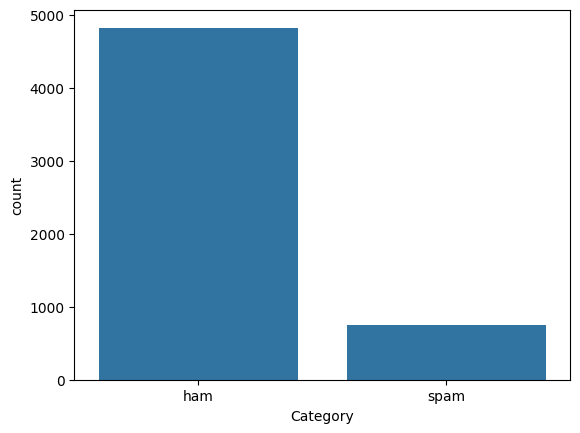

In [19]:
sns.countplot(x='Category', data = df)

**Pré-Processamento**

In [20]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("wordnet")
nltk.download('punkt_tab')

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    tokens = word_tokenize(text)
    stop_words = set(stopwords.words("english"))
    tokens = [word for word in tokens if word not in stop_words]
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(tokens)

df["clean_text"] = df["Message"].apply(preprocess_text)

# Texto que vai para o DistilBERT: "text" (recomendado) ou "clean_text"
TEXT_COLUMN = "Message"

[nltk_data] Downloading package stopwords to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [21]:
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['Category'])
le.classes_

array(['ham', 'spam'], dtype=object)

In [22]:
df.head(5)

,Category,Message,clean_text,label_encoded
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...,0
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...,1
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though,0


**Divisão treino/teste**

In [23]:
X = df[TEXT_COLUMN]
y = df['label_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#, stratify=y

# Conferência: o exemplo 499 deve ser o mesmo tweet usado no MLP
print("Índice original do exemplo 499:", X_test.index[499])
print("clean_text (como no MLP):", df.loc[X_test.index[499], "clean_text"])
print("Texto que o DistilBERT verá:", X_test.iloc[499])

Índice original do exemplo 499: 3912
clean_text (como no MLP): noe shes da car later c lar im wearing short
Texto que o DistilBERT verá: How i noe... She's in da car now... Later then c lar... I'm wearing shorts...


In [24]:
# Validação = 10% finais do treino, exatamente como validation_split=0.1 do Keras
split_at = int(len(X_train) * (1 - 0.1))
X_tr, X_val = X_train.iloc[:split_at], X_train.iloc[split_at:]
y_tr, y_val = y_train.iloc[:split_at], y_train.iloc[split_at:]
print("Treino:", len(X_tr), "| Validação:", len(X_val), "| Teste:", len(X_test))

Treino: 4011 | Validação: 446 | Teste: 1115


**Tokenização**

In [25]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Verificar o tamanho dos tweets em tokens para escolher MAX_LEN
lens = [len(tokenizer.encode(t)) for t in X_train]
print("Percentis 50/95/99/máx:", np.percentile(lens, [50, 95, 99]), max(lens))

MAX_LEN = 64
print(f"Tweets cobertos sem truncar: {np.mean(np.array(lens) <= MAX_LEN):.2%}")

Percentis 50/95/99/máx: [20.   55.   78.44] 238
Tweets cobertos sem truncar: 98.29%


In [26]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding="max_length",
                             max_length=MAX_LEN, return_tensors="pt")
        self.labels = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

BATCH_SIZE = 32  # mesmo batch do MLP; reduza para 16 se faltar memória

train_loader = DataLoader(TweetDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TweetDataset(X_val, y_val), batch_size=BATCH_SIZE)

**DistilBERT**

In [28]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: c for i, c in enumerate(le.classes_)},
    label2id={c: i for i, c in enumerate(le.classes_)},
    attn_implementation="eager",   # necessário para extrair os pesos de atenção
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parâmetros: {n_params:,}")

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parâmetros: 66,955,010


In [29]:
# Hiperparâmetros usuais de fine-tuning
EPOCHS = 3
LR = 2e-5

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.set_grad_enabled(train):
            out = model(**batch)
            if train:
                optimizer.zero_grad()
                out.loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
        bs = batch["labels"].size(0)
        tot_loss += out.loss.item() * bs
        correct += (out.logits.argmax(-1) == batch["labels"]).sum().item()
        n += bs
    return tot_loss / n, correct / n

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_loss, best_state = float("inf"), None

for epoch in range(EPOCHS):
    loss, acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, [loss, acc, val_loss, val_acc]):
        history[k].append(v)
    print(f"Epoch {epoch+1}/{EPOCHS} - accuracy: {acc:.4f} - loss: {loss:.4f} "
          f"- val_accuracy: {val_acc:.4f} - val_loss: {val_loss:.4f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

# Restaura a época com menor val_loss (defina RESTORE_BEST=False para usar a última, como no MLP)
RESTORE_BEST = True
if RESTORE_BEST:
    model.load_state_dict(best_state)
    print("Modelo restaurado para a melhor época (menor val_loss).")

Epoch 1/3 - accuracy: 0.9354 - loss: 0.1943 - val_accuracy: 0.9776 - val_loss: 0.0823
Epoch 2/3 - accuracy: 0.9943 - loss: 0.0214 - val_accuracy: 0.9776 - val_loss: 0.0963
Epoch 3/3 - accuracy: 0.9975 - loss: 0.0110 - val_accuracy: 0.9821 - val_loss: 0.0896
Modelo restaurado para a melhor época (menor val_loss).


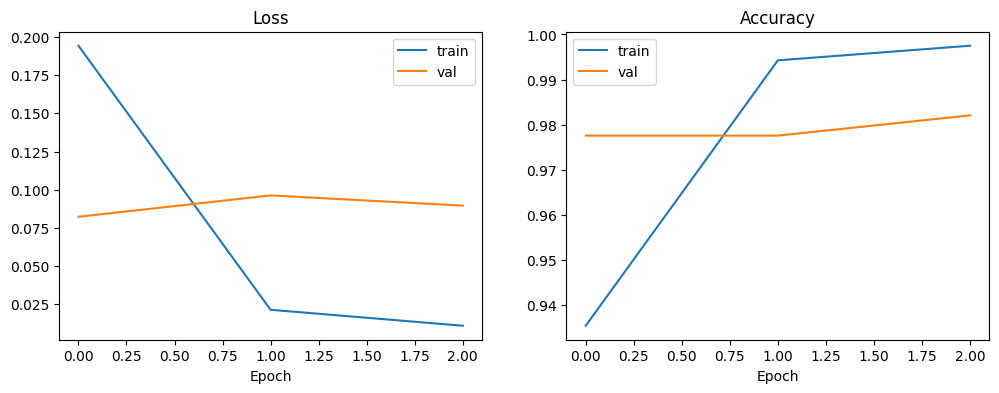

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history["accuracy"], label="train"); ax[1].plot(history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

**Métricas**

In [31]:
@torch.no_grad()
def predict_proba(texts, batch_size=64):
    """Recebe lista de strings e devolve probabilidades (n, 3). Usada nas métricas, no LIME e no SHAP."""
    model.eval()
    texts = [str(t) for t in texts]
    probs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i+batch_size], truncation=True, padding=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
        probs.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.vstack(probs)

y_pred = predict_proba(X_test.tolist())
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       966
           1       0.98      0.96      0.97       149

    accuracy                           0.99      1115
   macro avg       0.99      0.98      0.98      1115
weighted avg       0.99      0.99      0.99      1115



In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score
def calculate_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1

accuracy, precision, recall, f1 = calculate_metrics(y_test, y_pred_classes)
print(f"Acurácia: {accuracy:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"F1-Score (macro): {f1_score(y_test, y_pred_classes, average='macro'):.4f}  # mais sensível ao desbalanceamento")

Acurácia: 0.9919
Precisão: 0.9919
Recall: 0.9919
F1-Score: 0.9919
F1-Score (macro): 0.9824  # mais sensível ao desbalanceamento


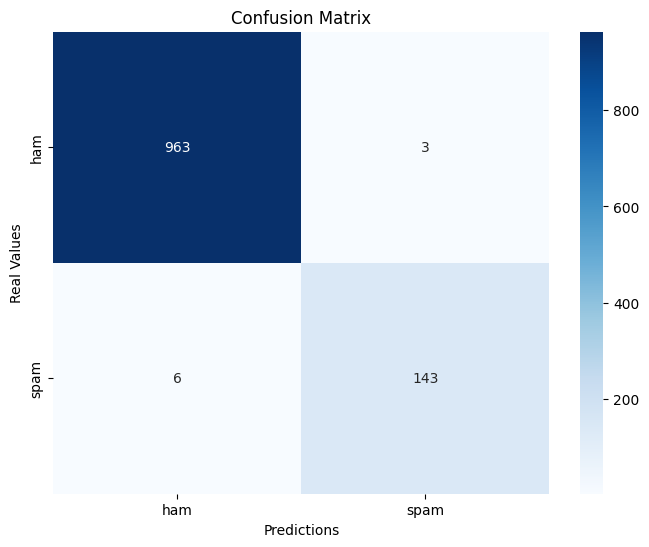

In [33]:
conf_matrix = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predictions")
plt.ylabel("Real Values")
plt.title("Confusion Matrix")
plt.show()

**LIME**

In [34]:
explainer = LimeTextExplainer(class_names=le.classes_)

idx = int(input(f"Digite o número da linha (0 a {len(X_test)-1}): ") or 499)
sample_text = X_test.iloc[idx]
sample_label = y_test.iloc[idx]

pred_probs = predict_proba([sample_text])
pred_class_idx = pred_probs.argmax(axis=1)[0]
pred_class_name = le.classes_[pred_class_idx]

print(f"Número da linha no X_test: {idx}")
print(f"Original text:\n{sample_text}")
print(f"Classe real: {le.classes_[sample_label]}")
print(f"Classe predita: {pred_class_name}")
print("Probabilidades:", pred_probs[0])

# labels=(pred_class_idx,) explica a classe predita (no MLP o LIME explicou a classe 1 por padrão)
explanation = explainer.explain_instance(
    sample_text,
    predict_proba,
    num_features=10,
    labels=(pred_class_idx,)
)

lime_features = explanation.as_list(label=pred_class_idx)
print(lime_features)

Número da linha no X_test: 499
Original text:
How i noe... She's in da car now... Later then c lar... I'm wearing shorts...
Classe real: ham
Classe predita: ham
Probabilidades: [0.99619496 0.003805  ]
[(np.str_('lar'), 0.0001859765268513459), (np.str_('noe'), 0.00013362149901274614), (np.str_('She'), 7.433536961916289e-05), (np.str_('I'), 6.784529786325506e-05), (np.str_('c'), 5.935439238768017e-05), (np.str_('da'), 5.616181945200939e-05), (np.str_('i'), 5.11293507888765e-05), (np.str_('then'), 4.075972116368952e-05), (np.str_('Later'), 3.527900026387933e-05), (np.str_('m'), 3.427944706755778e-05)]


Palavras mais importantes e seus pesos:
lar: 0.0002
noe: 0.0001
She: 0.0001
I: 0.0001
c: 0.0001
da: 0.0001
i: 0.0001
then: 0.0000
Later: 0.0000
m: 0.0000


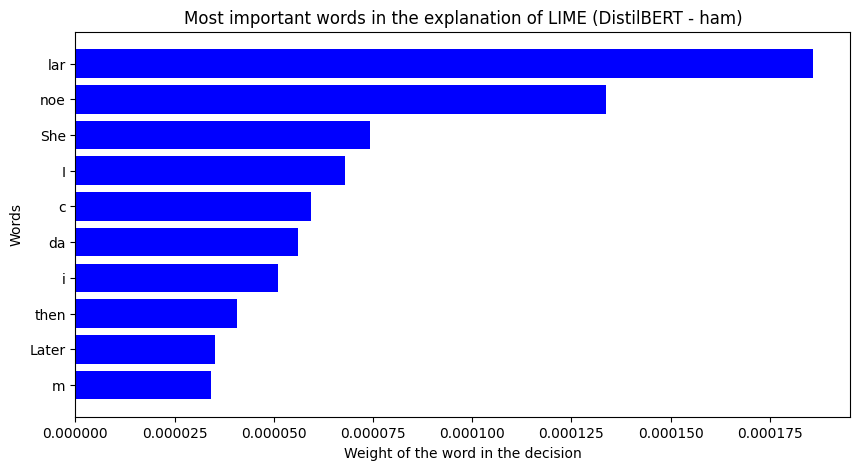

In [35]:
print("Palavras mais importantes e seus pesos:")
for word, weight in lime_features:
    print(f"{word}: {weight:.4f}")

words, weights = zip(*lime_features)
plt.figure(figsize=(10, 5))
plt.barh(words, weights, color="blue")
plt.xlabel("Weight of the word in the decision")
plt.ylabel("Words")
plt.title(f"Most important words in the explanation of LIME (DistilBERT - {pred_class_name})")
plt.gca().invert_yaxis()
plt.show()

**Attention Viz**

In [36]:
lime_idx = 499
sample_text = X_test.iloc[lime_idx]
print("Texto usado na explicação:")
print(sample_text)

enc = tokenizer(sample_text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
model.eval()
with torch.no_grad():
    out = model(**enc, output_attentions=True)

predicted_class_index = out.logits.argmax(-1).item()
print(f"\nClasse prevista: {predicted_class_index} ({le.classes_[predicted_class_index]})")
print("Probabilidades:", torch.softmax(out.logits, -1)[0].cpu().numpy())

# (camadas, cabeças, seq, seq)
att = torch.stack(out.attentions)[:, 0].cpu()
print("Atenções:", tuple(att.shape))

# 1) Última camada: [CLS] -> tokens, média das cabeças
last_cls = att[-1].mean(0)[0].numpy()

# 2) Attention rollout
seq = att.shape[-1]
rollout = torch.eye(seq)
for layer in att:
    a = layer.mean(0) + torch.eye(seq)
    a = a / a.sum(-1, keepdim=True)
    rollout = a @ rollout
rollout_cls = rollout[0].numpy()

tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])

def merge_subwords(tokens, scores):
    """Junta subpalavras (##) em palavras somando os escores e remove [CLS]/[SEP]."""
    words, vals = [], []
    for t, s in zip(tokens, scores):
        if t in ("[CLS]", "[SEP]", "[PAD]"):
            continue
        if t.startswith("##") and words:
            words[-1] += t[2:]; vals[-1] += s
        else:
            words.append(t); vals.append(s)
    return words, np.array(vals)

w_last, v_last = merge_subwords(tokens, last_cls)
w_roll, v_roll = merge_subwords(tokens, rollout_cls)

importancias = pd.DataFrame({"Feature": w_last, "Last layer [CLS]": v_last, "Rollout": v_roll})
importancias = importancias.sort_values(by="Rollout", ascending=False)
print(importancias.head(20))

Texto usado na explicação:
How i noe... She's in da car now... Later then c lar... I'm wearing shorts...

Classe prevista: 0 (ham)
Probabilidades: [0.99619496 0.003805  ]
Atenções: (6, 12, 35, 35)
    Feature  Last layer [CLS]   Rollout
30        .          0.044586  0.039767
2       noe          0.054642  0.025595
19      lar          0.058266  0.025173
29        .          0.041942  0.024631
28        .          0.041029  0.022896
14        .          0.037423  0.021494
21        .          0.036561  0.021130
15        .          0.041050  0.020835
4         .          0.038088  0.020375
22        .          0.043533  0.020182
3         .          0.037245  0.020051
13        .          0.036592  0.019913
5         .          0.042755  0.019859
9        in          0.007977  0.019377
20        .          0.033711  0.019362
18        c          0.040444  0.015396
0       how          0.039090  0.014902
26  wearing          0.004440  0.014711
16    later          0.018930  0.013903
1  

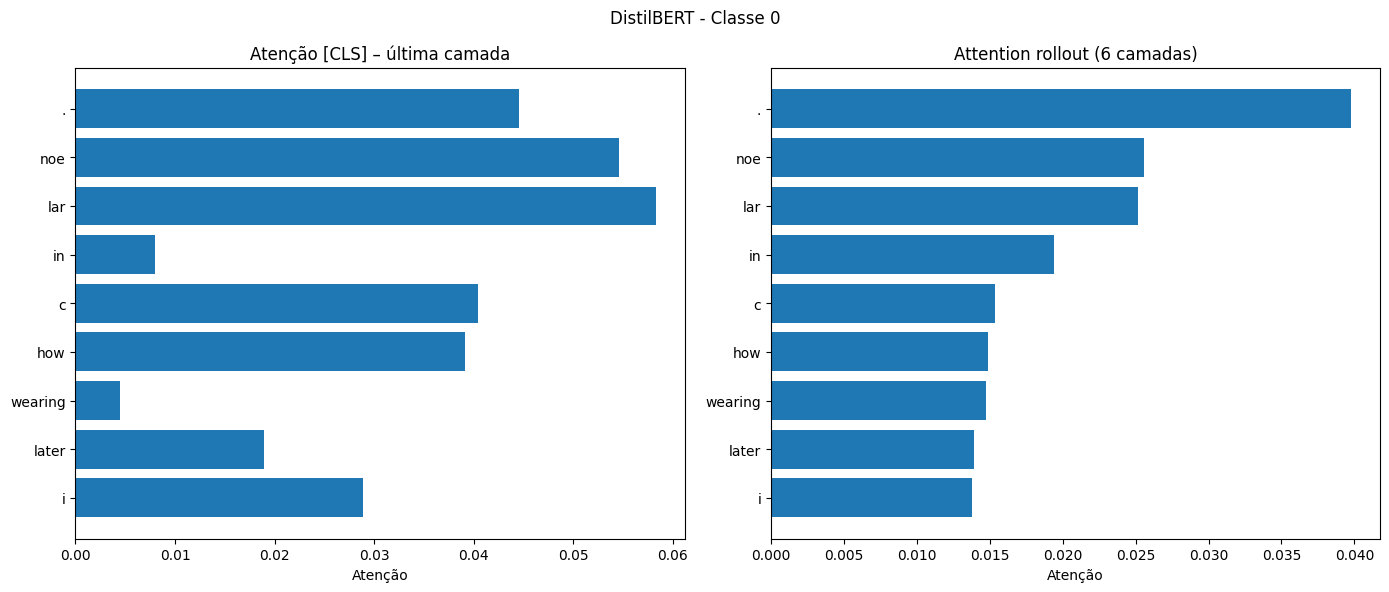

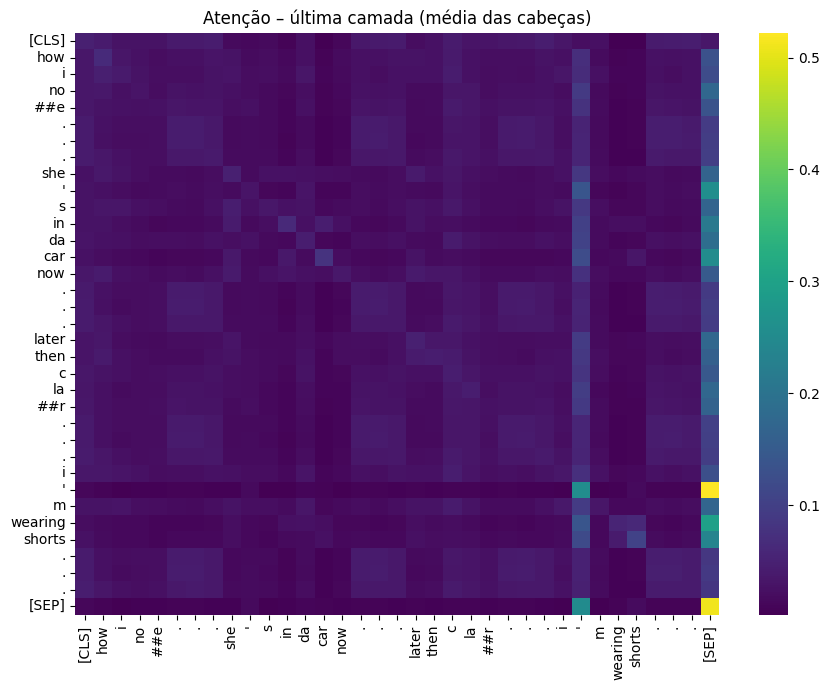

In [37]:
top = importancias.head(20)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(top["Feature"], top["Last layer [CLS]"])
ax[0].set_title("Atenção [CLS] – última camada"); ax[0].invert_yaxis()
ax[1].barh(top["Feature"], top["Rollout"])
ax[1].set_title("Attention rollout (6 camadas)"); ax[1].invert_yaxis()
for a in ax: a.set_xlabel("Atenção")
fig.suptitle(f"DistilBERT - Classe {predicted_class_index}")
plt.tight_layout(); plt.show()

# Mapa de calor da última camada (média das cabeças)
plt.figure(figsize=(9, 7))
sns.heatmap(att[-1].mean(0).numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("Atenção – última camada (média das cabeças)")
plt.tight_layout(); plt.show()

**Shapley**

In [38]:
lime_idx = 499
sample_text = X_test.iloc[lime_idx]

pred_class_idx = predict_proba([sample_text]).argmax(axis=1)[0]
print("Classe prevista:", pred_class_idx, le.classes_[pred_class_idx])

masker = shap.maskers.Text(tokenizer)
shap_explainer = shap.Explainer(lambda x: predict_proba(list(x)), masker,
                                output_names=list(le.classes_))

shap_values = shap_explainer([sample_text])

sv = shap_values[0, :, pred_class_idx]
words = np.array(sv.data)
values = np.array(sv.values)
expected_value = float(sv.base_values)

order = np.argsort(np.abs(values))[::-1][:15]
print("Palavras:", words[order])
print("SHAP:", values[order])
print("Valor base:", expected_value)

Classe prevista: 0 ham



PartitionExplainer explainer: 2it [01:44, 104.60s/it]              

Palavras: ['no' 'da ' '.' '.' '.' '. ' '. ' '.' 'i ' '. ' 'I' 'la' 'She' 'How ' '.']
SHAP: [0.01207354 0.01102251 0.01078471 0.01032297 0.01020427 0.00953364
 0.00917457 0.00916966 0.00893176 0.00873685 0.00870327 0.00859158
 0.00828267 0.00668964 0.00654619]
Valor base: 0.8092923164367676


In [39]:
# Visualização interativa no texto
shap.plots.text(shap_values[0, :, pred_class_idx])

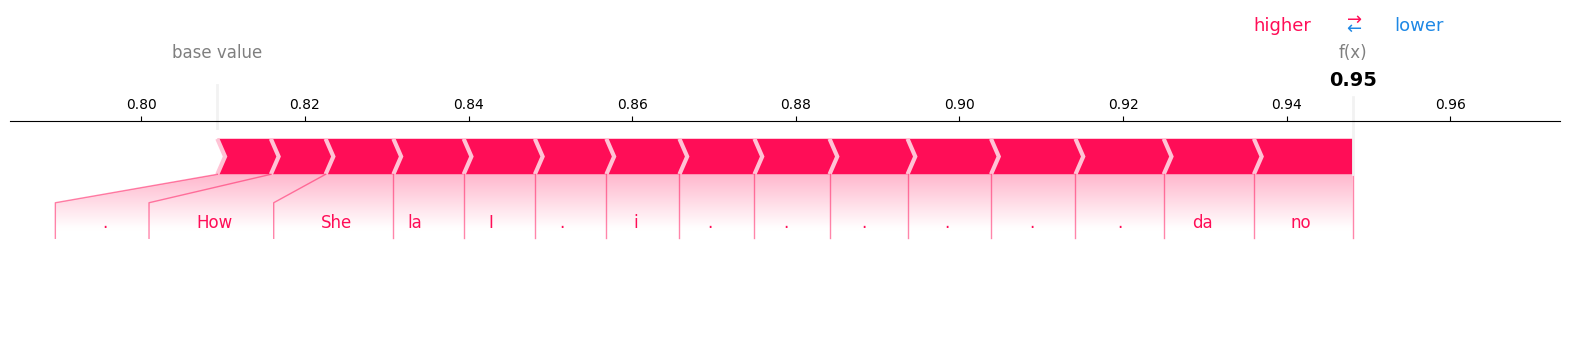

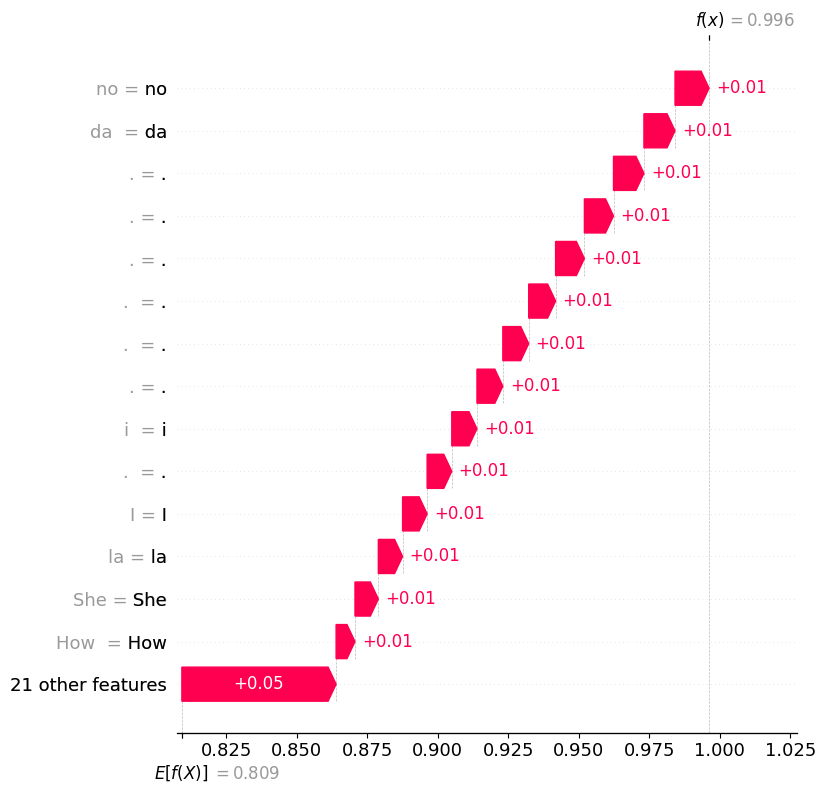

In [40]:
# Force plot (mesmo formato do notebook do MLP)
shap.force_plot(
    base_value=expected_value,
    shap_values=values[order],
    feature_names=[w.strip() for w in words[order]],
    matplotlib=True
)

# Waterfall
shap.plots.waterfall(sv, max_display=15)

**Salvar modelo e resultados** (para comparar os 5 modelos depois)

In [41]:
import json
model.save_pretrained("distilbert_imbalanced")
tokenizer.save_pretrained("distilbert_imbalanced")

resultados = {
    "modelo": "DistilBERT", "cenario": "imbalanced", "texto": TEXT_COLUMN,
    "accuracy": accuracy, "precision_w": precision, "recall_w": recall, "f1_w": f1,
    "f1_macro": f1_score(y_test, y_pred_classes, average="macro"),
    "epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE, "max_len": MAX_LEN,
}
with open("resultados_distilbert_imbalanced.json", "w") as f:
    json.dump(resultados, f, indent=2)
resultados

{'modelo': 'DistilBERT',
 'cenario': 'imbalanced',
 'texto': 'Message',
 'accuracy': 0.9919282511210762,
 'precision_w': 0.9918896251262572,
 'recall_w': 0.9919282511210762,
 'f1_w': 0.9918934654998401,
 'f1_macro': 0.9824201813165157,
 'epochs': 3,
 'lr': 2e-05,
 'batch_size': 32,
 'max_len': 64}